<a href="https://colab.research.google.com/github/miriamamin1213-ux/Ablation_studies/blob/main/HancockANN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using device: cpu
Mounted at /content/drive
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done

FOLD 1/3
Fold 1 | Epoch 1/500 | Train loss=0.6935 | Val loss=0.6912 | ROC-AUC=0.7473 | PR-AUC=0.7003
Fold 1 | Epoch 25/500 | Train loss=0.4812 | Val loss=0.6057 | ROC-AUC=0.7443 | PR-AUC=0.7226
Fold 1 | Epoch 50/500 | Train loss=0.4106 | Val loss=0.6909 | ROC-AUC=0.7204 | PR-AUC=0.7131
Fold 1 | Epoch 75/500 | Train loss=0.3501 | Val loss=0.7591 | ROC-AUC=0.7141 | PR-AUC=0.7066
Fold 1 | Epoch 100/500 | Train loss=0.3340 | Val loss=0.8047 | ROC-AUC=0.7051 | PR-AUC=0.6997
Fold 1 | Epoch 125/500 | Train loss=0.3422 | Val loss=0.8828 | ROC-AUC=0.6988 | PR-AUC=0.6920
Fold 1 | Epoch 150/500 | Train loss=0.3202 | Val loss=0.9342 | ROC-AUC=0.6971 | PR-AUC=0.6925
Fold 1 | Epoch 175/500 | Train loss=0.3003 | Val loss=0.9875 | ROC-AUC=0.6932 | PR-AUC=0.6895
Fold 1 | Epoch 200/500 | Train loss=0.3057 | Val loss=1.0086 | R

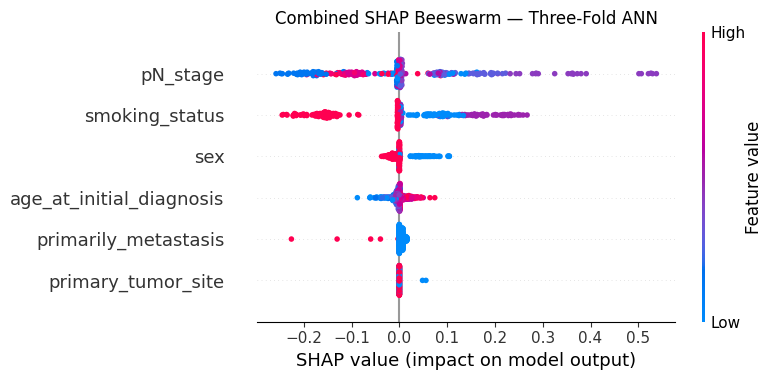

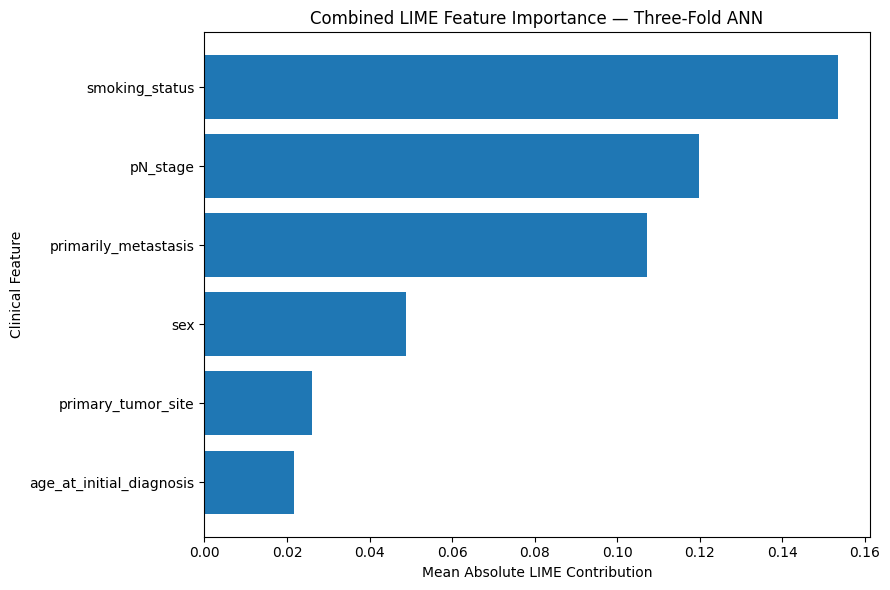


Completed 3-fold ANN, SHAP and LIME.
All outputs saved to: /content/drive/MyDrive/ANN_results/3_fold_CV


In [1]:

# ============================================================
# ANN — HANCOCK HPV CLASSIFIER
# GPT-2-aligned data preparation | Seed 42 | No SMOTE
# Full 500 epochs | Four validation-selected checkpoints
# ============================================================

import os
import json
import random
import copy
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from google.colab import drive

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
MAX_EPOCHS = 500
BATCH_SIZE = 32


def seed_everything(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

drive.mount("/content/drive")


# ------------------------------------------------------------
# 1. LOAD AND PREPARE DATA
# ------------------------------------------------------------

BASE = "/content/drive/MyDrive"
OUT_DIR = os.path.join(BASE, "ANN_results")
CHECKPOINT_DIR = os.path.join(OUT_DIR, "checkpoints")

os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)


def load_json_table(path):
    with open(path, "r", encoding="utf-8") as f:
        obj = json.load(f)

    if isinstance(obj, list):
        return pd.DataFrame(obj)

    if isinstance(obj, dict):
        for key in ["data", "records", "patients", "items"]:
            if key in obj and isinstance(obj[key], list):
                return pd.DataFrame(obj[key])

        return pd.DataFrame(obj)

    raise ValueError(f"Cannot read table from {path}")


clinical = load_json_table(
    os.path.join(BASE, "clinical_data.json")
)

pathology = load_json_table(
    os.path.join(BASE, "pathological_data.json")
)

if "patient_id" not in clinical or "patient_id" not in pathology:
    raise KeyError("Both files must contain patient_id.")

# Same left join as the GPT-2 notebook.
df = clinical.merge(
    pathology,
    on="patient_id",
    how="left",
    suffixes=("", "_path")
)

# Same target priority as the GPT-2 notebook.
target_candidates = [
    "hpv_association_p16",
    "hpv_association_p16_path"
]

target_col = next(
    (c for c in target_candidates if c in df.columns),
    None
)

if target_col is None:
    raise KeyError("HPV target column was not found.")


# Same feature set and fallback approach as the reference notebook.
feature_candidates = {
    "age_at_initial_diagnosis": [
        "age_at_initial_diagnosis"
    ],
    "sex": [
        "sex"
    ],
    "smoking_status": [
        "smoking_status"
    ],
    "primary_tumor_site": [
        "primary_tumor_site"
    ],
    "primarily_metastasis": [
        "primarily_metastasis"
    ],
    "pN_stage": [
        "pN_stage",
        "pN_stage_path",
        "pathological_N_stage",
        "pathological_n_stage"
    ]
}

rename_map = {}

for name, candidates in feature_candidates.items():
    match = next(
        (c for c in candidates if c in df.columns),
        None
    )

    if match is None:
        raise KeyError(
            f"Missing predictor {name}; checked {candidates}"
        )

    if match != name:
        rename_map[match] = name

df = df.rename(columns=rename_map)
features = list(feature_candidates.keys())


# Normalize the binary target using the GPT-2 approach.
def normalize_label(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip().lower()

    if value in {"negative", "neg", "0", "false", "no"}:
        return 0

    if value in {"positive", "pos", "1", "true", "yes"}:
        return 1

    try:
        number = float(value)

        if number in (0.0, 1.0):
            return int(number)

    except (ValueError, TypeError):
        pass

    return np.nan


df["HPV_Label"] = df[target_col].map(normalize_label)
df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)

df = df[["patient_id"] + features + ["HPV_Label"]].copy()



# ============================================================
# 2. THREE-FOLD STRATIFIED CV — ANN + SHAP + LIME
# ============================================================

!pip install -q shap lime

import shap
from lime.lime_tabular import LimeTabularExplainer
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix
)

from torch.utils.data import TensorDataset, DataLoader

# Original settings retained
SEED = 42
MAX_EPOCHS = 500
BATCH_SIZE = 32

numeric_features = ["age_at_initial_diagnosis"]
categorical_features = [c for c in features if c not in numeric_features]

thresholds = np.linspace(0.10, 0.90, 161)

checkpoint_specs = {
    "best_val_loss": "ann_best_val_loss.pt",
    "best_val_roc_auc": "ann_best_val_roc_auc.pt",
    "best_val_pr_auc": "ann_best_val_pr_auc.pt",
    "best_val_balanced_accuracy": "ann_best_val_balanced_accuracy.pt"
}

CV_DIR = os.path.join(OUT_DIR, "3_fold_CV")
os.makedirs(CV_DIR, exist_ok=True)

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

fold_runs = []
cv_metrics = []
all_histories = []

# ------------------------------------------------------------
# 3. TRAIN AND VALIDATE EACH FOLD
# ------------------------------------------------------------

for fold, (train_idx, val_idx) in enumerate(
    skf.split(df[features], df["HPV_Label"]), 1
):

    print(f"\n{'='*60}\nFOLD {fold}/3\n{'='*60}")

    seed_everything(SEED)

    train = df.iloc[train_idx].reset_index(drop=True)
    val = df.iloc[val_idx].reset_index(drop=True)

    X_train_df = train[features].copy()
    X_val_df = val[features].copy()

    # Train-only imputation
    for frame in [X_train_df, X_val_df]:
        frame["age_at_initial_diagnosis"] = pd.to_numeric(
            frame["age_at_initial_diagnosis"], errors="coerce"
        )

    age_median = X_train_df["age_at_initial_diagnosis"].median()
    if pd.isna(age_median):
        age_median = 0.0

    for frame in [X_train_df, X_val_df]:
        frame["age_at_initial_diagnosis"] = (
            frame["age_at_initial_diagnosis"].fillna(age_median)
        )

    for col in categorical_features:
        for frame in [X_train_df, X_val_df]:
            frame[col] = frame[col].astype("object").replace(
                r"^\s*$", np.nan, regex=True
            ).replace(["nan", "None", "NaN"], np.nan)

        modes = X_train_df[col].mode(dropna=True)
        fill_value = str(modes.iloc[0]) if not modes.empty else "Unknown"

        for frame in [X_train_df, X_val_df]:
            frame[col] = frame[col].fillna(fill_value).astype(str)
            frame[col] = frame[col].replace(
                ["", "nan", "None", "NaN"], "Unknown"
            )

    try:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

    preprocessor = ColumnTransformer([
        ("num", StandardScaler(), numeric_features),
        ("cat", encoder, categorical_features)
    ])

    X_train = preprocessor.fit_transform(X_train_df).astype(np.float32)
    X_val = preprocessor.transform(X_val_df).astype(np.float32)

    y_train = train["HPV_Label"].to_numpy().astype(np.int64)
    y_val = val["HPV_Label"].to_numpy().astype(np.int64)

    # Fold-specific class weights
    counts = np.bincount(y_train, minlength=2)
    if np.any(counts == 0):
        raise ValueError(f"Both classes must be present in fold {fold}.")

    weights = len(y_train) / (2.0 * counts)
    class_weights = torch.tensor(
        weights, dtype=torch.float32, device=device
    )

    train_dataset = TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.long)
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED)
    )

    X_val_t = torch.tensor(X_val, dtype=torch.float32, device=device)
    y_val_t = torch.tensor(y_val, dtype=torch.long, device=device)

    # Original ANN architecture
    class ANNClassifier(nn.Module):
        def __init__(self, input_dim):
            super().__init__()
            self.network = nn.Sequential(
                nn.Linear(input_dim, 64),
                nn.ReLU(),
                nn.Dropout(0.30),
                nn.Linear(64, 32),
                nn.ReLU(),
                nn.Dropout(0.20),
                nn.Linear(32, 16),
                nn.ReLU(),
                nn.Linear(16, 2)
            )

        def forward(self, x):
            return self.network(x)

    model = ANNClassifier(X_train.shape[1]).to(device)

    criterion = nn.CrossEntropyLoss(
        weight=class_weights, reduction="none"
    )

    optimizer = torch.optim.Adam(
        model.parameters(), lr=0.001, weight_decay=1e-4
    )

    def predict_probabilities(model, X):
        model.eval()
        with torch.no_grad():
            return torch.softmax(
                model(torch.tensor(X, dtype=torch.float32, device=device)),
                dim=1
            )[:, 1].cpu().numpy()

    def select_threshold(y_true, probabilities):
        scores = [
            balanced_accuracy_score(
                y_true, (probabilities >= t).astype(int)
            )
            for t in thresholds
        ]
        best_score = max(scores)
        best_threshold = min(
            (t for t, s in zip(thresholds, scores)
             if np.isclose(s, best_score)),
            key=lambda t: abs(t - 0.5)
        )
        return float(best_threshold), float(best_score)

    best_values = {
        "best_val_loss": float("inf"),
        "best_val_roc_auc": -float("inf"),
        "best_val_pr_auc": -float("inf"),
        "best_val_balanced_accuracy": -float("inf")
    }

    best_epochs = {}
    fold_history = []
    fold_checkpoints = {}

    # Train all 500 epochs; no early stopping
    for epoch in range(1, MAX_EPOCHS + 1):

        model.train()
        running_loss, seen = 0.0, 0

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)

            optimizer.zero_grad()
            logits = model(xb)
            per_example_loss = criterion(logits, yb)
            loss = per_example_loss.mean()
            loss.backward()
            optimizer.step()

            running_loss += per_example_loss.detach().sum().item()
            seen += len(yb)

        train_loss = running_loss / max(seen, 1)

        model.eval()
        with torch.no_grad():
            val_loss = criterion(model(X_val_t), y_val_t).mean().item()

        val_prob = predict_probabilities(model, X_val)
        threshold, bal_acc = select_threshold(y_val, val_prob)

        roc_auc = (
            roc_auc_score(y_val, val_prob)
            if len(np.unique(y_val)) == 2 else np.nan
        )
        pr_auc = average_precision_score(y_val, val_prob)

        fold_history.append({
            "fold": fold, "epoch": epoch,
            "train_loss": train_loss, "val_loss": val_loss,
            "val_roc_auc": roc_auc, "val_pr_auc": pr_auc,
            "val_balanced_accuracy": bal_acc,
            "val_threshold": threshold
        })

        values = {
            "best_val_loss": val_loss,
            "best_val_roc_auc": roc_auc,
            "best_val_pr_auc": pr_auc,
            "best_val_balanced_accuracy": bal_acc
        }

        for name, value in values.items():
            direction_ok = (
                value < best_values[name] if name == "best_val_loss"
                else value > best_values[name]
            )

            if np.isfinite(value) and direction_ok:
                best_values[name] = float(value)
                best_epochs[name] = epoch

                checkpoint = {
                    "epoch": epoch,
                    "model_state_dict": copy.deepcopy(model.state_dict()),
                    "validation_loss": float(val_loss),
                    "validation_roc_auc": float(roc_auc),
                    "validation_pr_auc": float(pr_auc),
                    "validation_balanced_accuracy": float(bal_acc),
                    "validation_threshold": float(threshold)
                }

                fold_checkpoints[name] = checkpoint

        if epoch == 1 or epoch % 25 == 0:
            print(
                f"Fold {fold} | Epoch {epoch}/{MAX_EPOCHS} | "
                f"Train loss={train_loss:.4f} | "
                f"Val loss={val_loss:.4f} | "
                f"ROC-AUC={roc_auc:.4f} | PR-AUC={pr_auc:.4f}"
            )

    all_histories.extend(fold_history)

    # Save all four checkpoints for this fold
    fold_checkpoint_dir = os.path.join(CV_DIR, f"fold_{fold}")
    os.makedirs(fold_checkpoint_dir, exist_ok=True)

    for name, checkpoint in fold_checkpoints.items():
        path = os.path.join(fold_checkpoint_dir, checkpoint_specs[name])
        torch.save(checkpoint, path)

    fold_runs.append({
        "fold": fold,
        "train": train.copy(),
        "val": val.copy(),
        "X_train_df": X_train_df.copy(),
        "X_val_df": X_val_df.copy(),
        "X_train": X_train,
        "X_val": X_val,
        "y_train": y_train,
        "y_val": y_val,
        "preprocessor": preprocessor,
        "checkpoints": fold_checkpoints,
        "checkpoint_dir": fold_checkpoint_dir,
        "best_epochs": best_epochs
    })

    # Evaluate each checkpoint on this fold's validation set
    for name, checkpoint in fold_checkpoints.items():
        model.load_state_dict(checkpoint["model_state_dict"])
        val_prob = predict_probabilities(model, X_val)
        threshold, _ = select_threshold(y_val, val_prob)
        pred = (val_prob >= threshold).astype(int)

        cv_metrics.append({
            "Fold": fold,
            "Checkpoint": name,
            "Epoch": checkpoint["epoch"],
            "Threshold": threshold,
            "Accuracy": accuracy_score(y_val, pred),
            "Balanced_Accuracy": balanced_accuracy_score(y_val, pred),
            "Precision": precision_score(y_val, pred, zero_division=0),
            "Recall": recall_score(y_val, pred, zero_division=0),
            "F1": f1_score(y_val, pred, zero_division=0),
            "ROC_AUC": roc_auc_score(y_val, val_prob),
            "PR_AUC": average_precision_score(y_val, val_prob)
        })

    print("Fold", fold, "completed. Best epochs:", best_epochs)


# ------------------------------------------------------------
# 4. COMBINED THREE-FOLD RESULTS
# ------------------------------------------------------------

cv_metrics_df = pd.DataFrame(cv_metrics)
cv_metrics_df.to_csv(
    os.path.join(CV_DIR, "CV_fold_metrics.csv"), index=False
)

cv_average = (
    cv_metrics_df.groupby("Checkpoint")
    .agg(["mean", "std"])
)

cv_average.to_csv(
    os.path.join(CV_DIR, "CV_average_metrics.csv")
)

pd.DataFrame(all_histories).to_csv(
    os.path.join(CV_DIR, "all_fold_training_history.csv"),
    index=False
)

print("\nTHREE-FOLD CROSS-VALIDATION MEAN METRICS")
print(cv_metrics_df.groupby("Checkpoint")[
    ["Accuracy", "Balanced_Accuracy", "Precision",
     "Recall", "F1", "ROC_AUC", "PR_AUC"]
].mean().round(4))


# ------------------------------------------------------------
# 5. COMBINED SHAP — AVERAGE ACROSS ALL THREE FOLDS
# ------------------------------------------------------------

SHAP_CHECKPOINT = "best_val_roc_auc"
shap_rows = []
shap_data_rows = []

for run in fold_runs:

    fold = run["fold"]
    model = ANNClassifier(run["X_train"].shape[1]).to(device)
    model.load_state_dict(
        run["checkpoints"][SHAP_CHECKPOINT]["model_state_dict"]
    )
    model.eval()

    X_train = run["X_train"]
    X_val = run["X_val"]

    # Predict positive-class probability
    def shap_predict(x):
        return predict_probabilities(model, x)

    background = shap.sample(
        X_train, min(50, len(X_train)), random_state=SEED
    )

    explainer = shap.Explainer(
        shap_predict,
        shap.maskers.Independent(background),
        algorithm="permutation"
    )

    shap_values = explainer(
        X_val,
        max_evals=2 * X_train.shape[1] + 1
    )

    # Combine one-hot columns back into their original clinical feature
    grouped_values = np.zeros((len(X_val), len(features)))

    grouped_values[:, 0] = shap_values.values[:, 0]

    categories = run["preprocessor"].named_transformers_["cat"].categories_
    col_position = 1

    for j, col in enumerate(categorical_features, start=1):
        width = len(categories[j - 1])
        grouped_values[:, j] = shap_values.values[
            :, col_position:col_position + width
        ].sum(axis=1)
        col_position += width

    shap_rows.append(grouped_values)

    # Numeric display data for the combined beeswarm
    display_data = np.zeros((len(X_val), len(features)))
    display_data[:, 0] = run["X_val_df"][
        "age_at_initial_diagnosis"
    ].to_numpy()

    for j, col in enumerate(categorical_features, start=1):
        cats = list(categories[j - 1])
        display_data[:, j] = (
            run["X_val_df"][col].astype(str)
            .map({v: i for i, v in enumerate(cats)})
            .fillna(-1).to_numpy()
        )

    shap_data_rows.append(display_data)

combined_shap_values = np.concatenate(shap_rows, axis=0)
combined_shap_data = np.concatenate(shap_data_rows, axis=0)

shap_explanation = shap.Explanation(
    values=combined_shap_values,
    data=combined_shap_data,
    feature_names=features
)

plt.figure()
shap.plots.beeswarm(shap_explanation, show=False)
plt.title("Combined SHAP Beeswarm — Three-Fold ANN")
plt.tight_layout()
plt.savefig(
    os.path.join(CV_DIR, "Combined_SHAP_Beeswarm.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()

shap_importance = pd.DataFrame({
    "Feature": features,
    "Mean_Absolute_SHAP": np.abs(combined_shap_values).mean(axis=0)
}).sort_values("Mean_Absolute_SHAP", ascending=False)

shap_importance.to_csv(
    os.path.join(CV_DIR, "Combined_SHAP_Feature_Importance.csv"),
    index=False
)


# ------------------------------------------------------------
# 6. COMBINED LIME — AVERAGE ACROSS ALL THREE FOLDS
# ------------------------------------------------------------

LIME_CHECKPOINT = "best_val_roc_auc"
LIME_PATIENTS_PER_FOLD = None  # Explain every validation patient
LIME_NUM_SAMPLES = 500

lime_rows = []

for run in fold_runs:

    fold = run["fold"]
    model = ANNClassifier(run["X_train"].shape[1]).to(device)
    model.load_state_dict(
        run["checkpoints"][LIME_CHECKPOINT]["model_state_dict"]
    )
    model.eval()

    train_raw = run["X_train_df"].copy()
    val_raw = run["X_val_df"].copy()

    # Encode categorical columns for LIME's tabular representation
    category_maps = {}
    for col in categorical_features:
        category_maps[col] = sorted(
            train_raw[col].astype(str).unique().tolist()
        )

    def lime_encode(frame):
        result = np.zeros((len(frame), len(features)), dtype=float)

        result[:, 0] = frame[
            "age_at_initial_diagnosis"
        ].to_numpy(dtype=float)

        for j, col in enumerate(categorical_features, start=1):
            mapping = {
                value: i for i, value in enumerate(category_maps[col])
            }
            result[:, j] = (
                frame[col].astype(str).map(mapping).fillna(0).to_numpy()
            )

        return result

    def lime_decode(matrix):
        matrix = np.asarray(matrix)
        if matrix.ndim == 1:
            matrix = matrix.reshape(1, -1)

        decoded = pd.DataFrame(columns=features)
        decoded["age_at_initial_diagnosis"] = matrix[:, 0]

        for j, col in enumerate(categorical_features, start=1):
            cats = category_maps[col]
            codes = np.rint(matrix[:, j]).astype(int)
            codes = np.clip(codes, 0, len(cats) - 1)
            decoded[col] = [cats[k] for k in codes]

        return decoded[features]

    lime_train = lime_encode(train_raw)
    lime_val = lime_encode(val_raw)

    # Use this fold's fitted preprocessor for model predictions
    def lime_predict(matrix):
        raw = lime_decode(matrix)
        encoded = run["preprocessor"].transform(raw).astype(np.float32)
        return np.column_stack([
            1 - predict_probabilities(model, encoded),
            predict_probabilities(model, encoded)
        ])

    categorical_indices = list(range(1, len(features)))
    categorical_names = {
        i: category_maps[col]
        for i, col in zip(categorical_indices, categorical_features)
    }

    lime_explainer = LimeTabularExplainer(
        training_data=lime_train,
        feature_names=features,
        class_names=["HPV Negative", "HPV Positive"],
        categorical_features=categorical_indices,
        categorical_names=categorical_names,
        mode="classification",
        discretize_continuous=True,
        random_state=SEED
    )

    patient_count = (
        len(lime_val) if LIME_PATIENTS_PER_FOLD is None
        else min(LIME_PATIENTS_PER_FOLD, len(lime_val))
    )

    for patient_index in range(patient_count):

        explanation = lime_explainer.explain_instance(
            lime_val[patient_index],
            lime_predict,
            num_features=len(features),
            num_samples=LIME_NUM_SAMPLES,
            labels=[1]
        )

        for feature_index, contribution in explanation.as_map()[1]:
            lime_rows.append({
                "Fold": fold,
                "Patient": patient_index + 1,
                "Feature": features[feature_index],
                "Contribution": contribution
            })

lime_df = pd.DataFrame(lime_rows)

lime_summary = (
    lime_df.assign(
        Absolute_Contribution=lime_df["Contribution"].abs()
    )
    .groupby("Feature")
    .agg(
        Mean_Absolute_Contribution=("Absolute_Contribution", "mean"),
        Mean_Signed_Contribution=("Contribution", "mean")
    )
    .reset_index()
    .sort_values("Mean_Absolute_Contribution", ascending=True)
)

lime_df.to_csv(
    os.path.join(CV_DIR, "Combined_LIME_Patient_Results.csv"),
    index=False
)

lime_summary.to_csv(
    os.path.join(CV_DIR, "Combined_LIME_Feature_Importance.csv"),
    index=False
)

plt.figure(figsize=(9, 6))
plt.barh(
    lime_summary["Feature"],
    lime_summary["Mean_Absolute_Contribution"]
)
plt.xlabel("Mean Absolute LIME Contribution")
plt.ylabel("Clinical Feature")
plt.title("Combined LIME Feature Importance — Three-Fold ANN")
plt.tight_layout()
plt.savefig(
    os.path.join(CV_DIR, "Combined_LIME_Feature_Importance.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()

print("\nCompleted 3-fold ANN, SHAP and LIME.")
print("All outputs saved to:", CV_DIR)

